[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB12_brain_wiring.ipynb)

# Day 2 · Chapter 5 · Notebook 12 — The brain's wiring: what does a model need from it?

The slides introduced the connectome as a network (hubs, short connections, modules, gradients). A short recap on the
human connectome that our models use (100 regions, HCP), then a **virtual experiment** that is impossible in a real
brain: rewire it. The last section prepares the myelin map used in NB13b.

> **Question.** Which property of the wiring does a whole-brain model need to reproduce the measured FC?
> **Virtual experiment.** Give the same Hopf model fake connectomes that keep only one property of the real one.
> **What would change our mind.** If a fake that keeps only connection lengths fit as well as the real connectome, the
> specific pairs of regions would not matter.

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
# Load the human connectome, the measured FC and the region positions
from src import connectome, wholebrain
sc, fc, labels = connectome.load_hcp(weights="counts", normalize=False)      # fibre counts, empirical group FC
xyz = np.loadtxt("../data/connectome/centroids_ctx_schaefer_100.csv", delimiter=",", comments="#")   # region centres (mm)
net = np.array([l.split("_")[2] for l in labels])                 # resting-state network of each region (Yeo et al. 2011)
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
NETCOL = {n: f"C{k}" for k, n in enumerate(NETS)}
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]           # 1 = same pattern as the measured FC

def brain(ax, values, cmap="viridis", edges=None, title="", size=60, **kw):
    # view from above: x = left-right, y = back-front
    if edges is not None:
        for i, j in zip(*np.where(np.triu(edges))):
            ax.plot(xyz[[i, j], 0], xyz[[i, j], 1], c="0.6", lw=0.5, zorder=0)
    sc_ = ax.scatter(xyz[:, 0], xyz[:, 1], c=values, cmap=cmap, s=size, edgecolors="k", linewidths=0.4, **kw)
    ax.set(aspect="equal", xticks=[], yticks=[], title=title); [s.set_visible(False) for s in ax.spines.values()]
    ax.text(xyz[:, 0].min(), xyz[:, 1].max(), "front ↑", fontsize=8, color="0.4")
    return sc_
print(f"{len(labels)} regions; {(sc[u] > 0).mean():.0%} of all possible pairs are connected")

100 regions; 22% of all possible pairs are connected


## 1. Recap of the slides: hubs and short connections

> **Gist.** Row $i$, column $j$ of the matrix = number of fibres between regions $i$ and $j$ (diffusion MRI
> tractography). A few **hubs** have about three times the fibres of a typical region, and most connections are
> **short**: the probability that two regions are wired falls with their distance.

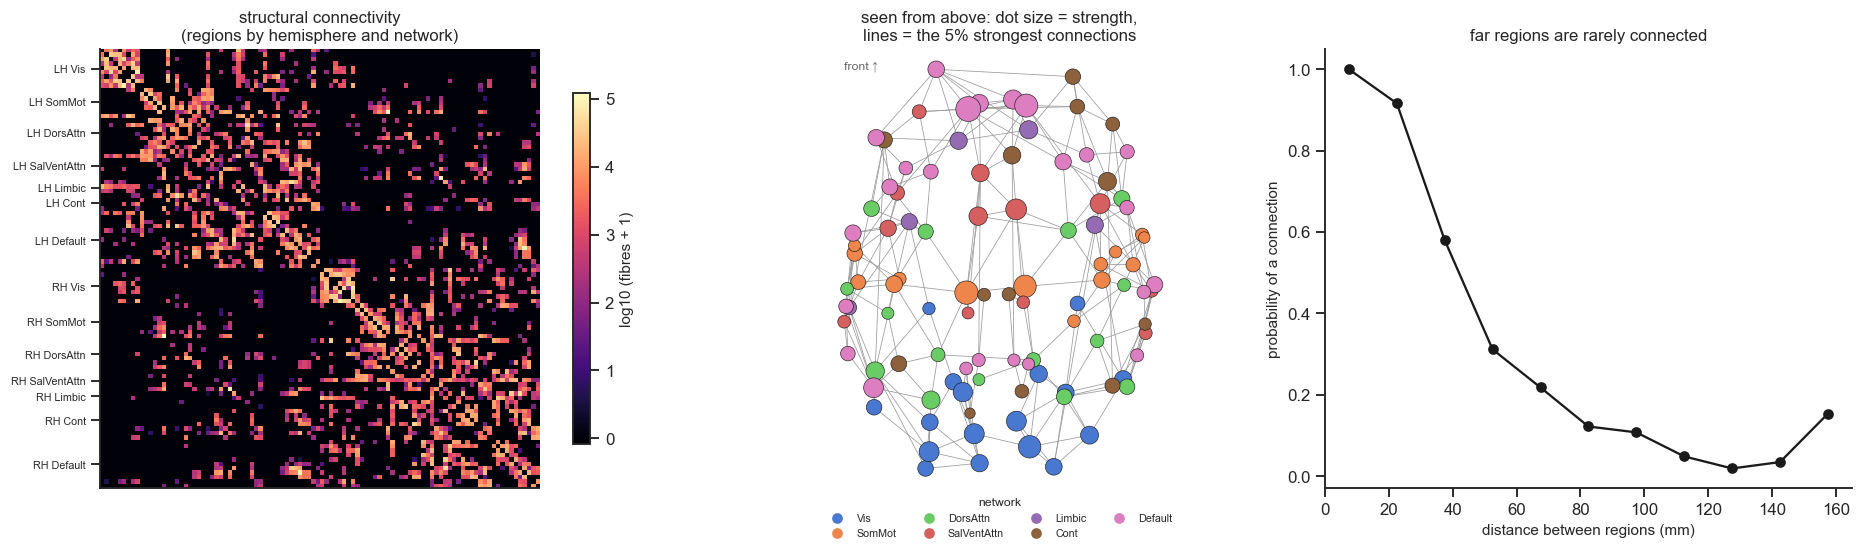

hub: LH_Default_PFC_5             307k fibres (median region 109k)
hub: LH_SomMot_6                  268k fibres (median region 109k)
hub: RH_Default_PFCdPFCm_2        261k fibres (median region 109k)
hub: RH_Vis_8                     247k fibres (median region 109k)
hub: RH_SomMot_8                  246k fibres (median region 109k)


In [2]:
# @title Connectivity matrix, brain seen from above (dot size = strength), connection probability vs distance
strength = sc.sum(1)                                                 # total number of fibres of each region
D = np.linalg.norm(xyz[:, None] - xyz[None], axis=-1)              # distance between region centres (mm)
d, w = D[u], sc[u]
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw=dict(width_ratios=[1.15, 1, 0.9]))
im = ax[0].imshow(np.log10(sc + 1), cmap="magma"); plt.colorbar(im, ax=ax[0], shrink=0.8, label="log10 (fibres + 1)")
edges_ = [0] + [k for k in range(1, 100) if net[k] != net[k - 1] or labels[k][10:12] != labels[k - 1][10:12]] + [100]
ax[0].set_xticks([]); ax[0].set_yticks((np.array(edges_[:-1]) + np.array(edges_[1:])) / 2 - 0.5,
                                       [f"{labels[k][10:12]} {net[k]}" for k in edges_[:-1]], fontsize=7)
ax[0].set_title("structural connectivity\n(regions by hemisphere and network)")
strong = sc >= np.quantile(sc[u], 0.95)                              # the 5% strongest connections
brain(ax[1], [NETCOL[n] for n in net], cmap=None, edges=strong, size=15 + 250 * strength / strength.max(),
      title="seen from above: dot size = strength,\nlines = the 5% strongest connections")
for n in NETS: ax[1].plot([], [], "o", c=NETCOL[n], label=n)
ax[1].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, title="network", title_fontsize=8)
bins = np.arange(0, 170, 15); mid = (bins[1:] + bins[:-1]) / 2
ax[2].plot(mid, [(w[(d >= a) & (d < b)] > 0).mean() for a, b in zip(bins[:-1], bins[1:])], "ko-")
ax[2].set(xlabel="distance between regions (mm)", ylabel="probability of a connection", title="far regions are rarely connected")
plt.tight_layout(); plt.show()
for k in np.argsort(-strength)[:5]:
    print(f"hub: {labels[k][10:]:28s} {strength[k] / 1000:.0f}k fibres (median region {np.median(strength) / 1000:.0f}k)")

Connections are dense within each hemisphere and sparse between them; the hubs (largest dots, list above) sit in
medial prefrontal, somatomotor and visual cortex. **Right:** the probability of a connection falls steeply with
distance. (The rise at the far right is noise: only 13 pairs are that far apart, two of them wired by long
back-to-front bundles.) (NB14a ranks
hubs by their weight in the model, which also counts the mirror links between hemispheres, so its list differs a little.)

<details><summary>Small world and modules (seen in the slides)</summary>

Keep the 40% strongest connections and compare the brain with a randomly rewired copy that keeps the number of
connections of every region. The brain is far more **clustered** (my neighbours are neighbours of each other), with
almost the same **path length** (about 3 steps between any two regions): a small world. Groups of densely
interconnected regions (**modules**) contain neighbouring regions. Homework 4 lets you compute this yourself.
</details>

## 2. Virtual experiment: rewire the brain

> **Hypothesis.** The model needs only the **geometry** of the wiring (nearby regions are wired), not which specific
> pairs are connected. **Test.** Build fake connectomes that keep **one** property of the real one, put each into the
> same Hopf model (NB10), and compare the model FC with the measured FC. Impossible in a real brain; a few seconds here.

* **random places:** the same list of fibre counts, given to random pairs of regions (keeps nothing but the numbers);
* **same lengths:** fibre counts exchanged only between connections of similar length (keeps the geometry).

<details><summary>Details (for the curious)</summary>

Hopf model with $a=-0.1$ and $G=2$ (the working point of NB13), 2 × 20 minutes per connectome. Only the
tractography part is scrambled: the mirror connections between hemispheres added in NB10 are the same in every
connectome. "Same lengths": the pairs are split into 20 distance bins and the fibre counts are permuted within each bin.
Three fakes of each kind (dots).
</details>

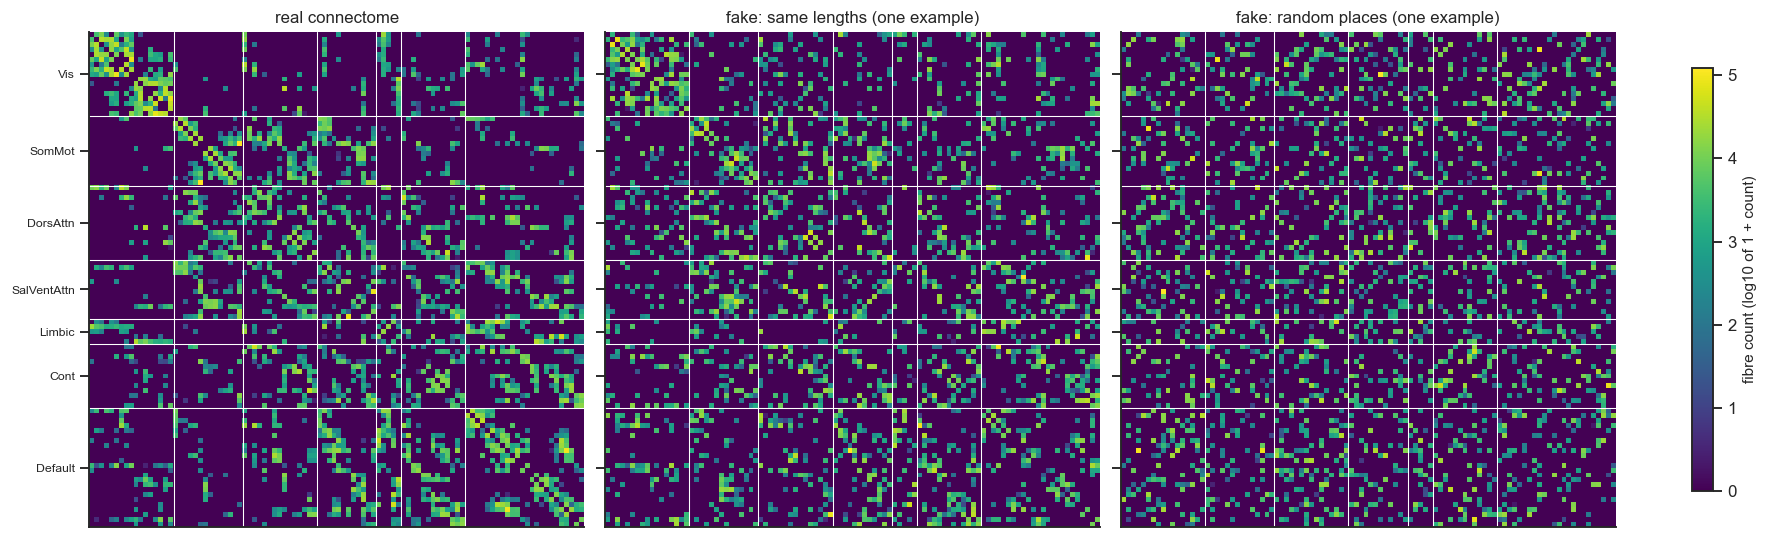

In [3]:
# @title Fake connectomes in the same Hopf model (a few seconds)
pairs = connectome.homotopic_pairs("schaefer100", labels)
def as_model_input(M):                                             # scaling and mirror links exactly as in NB10
    M = M / M.sum(1).max()
    for k, j in pairs: M[k, j] += 0.5; M[j, k] += 0.5
    return M

def fit(M, G=2.0, a=-0.1):
    F = np.mean([np.corrcoef(wholebrain.hopf_network(as_model_input(M), G, a=a, T=1200, TR=2.0, seed=s)[1].T) for s in range(2)], 0)
    return similarity(F, fc)

def from_upper(w):
    M = np.zeros((100, 100)); M[u] = w; return M + M.T

def random_places(M, rng):
    return from_upper(rng.permutation(M[u]))

def same_lengths(M, rng, n_bins=20):
    w = M[u].copy(); edges = np.quantile(d, np.linspace(0, 1, n_bins + 1))
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d >= lo) & (d <= hi); w[m] = rng.permutation(w[m])
    return from_upper(w)

rng = np.random.default_rng(0)
fakes = {"real connectome": [sc],
         "same lengths": [same_lengths(sc, rng) for _ in range(3)],
         "random places": [random_places(sc, rng) for _ in range(3)]}

order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network
bounds = np.cumsum([np.sum(net == n) for n in NETS])
fig, ax = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
for a_, (name, Ms) in zip(ax, fakes.items()):
    im = a_.imshow(np.log10(1 + Ms[0][np.ix_(order, order)]), cmap="viridis", vmin=0, vmax=np.log10(1 + sc.max()), interpolation="nearest")
    for e in bounds[:-1] - 0.5: a_.axhline(e, c="w", lw=0.7); a_.axvline(e, c="w", lw=0.7)
    a_.set_xticks([]); a_.set_yticks(np.r_[0, bounds[:-1]] + np.diff(np.r_[0, bounds]) / 2 - 0.5, NETS if a_ is ax[0] else [], fontsize=8)
    a_.set_title(name if name == "real connectome" else f"fake: {name} (one example)")
fig.colorbar(im, ax=ax, shrink=0.8, label="fibre count (log10 of 1 + count)")
plt.show()

Each matrix shows the wiring between all pairs of regions (dark: no fibres), sorted by resting-state network (white
lines; inside each network, left hemisphere first). **Real:** dense squares on the diagonal: regions of the same network,
in the same hemisphere, are wired together. **Same lengths:** part of these squares survives, because regions of one
network are often close to each other; the rest is scattered. **Random places:** the same numbers spread everywhere;
no structure is left.

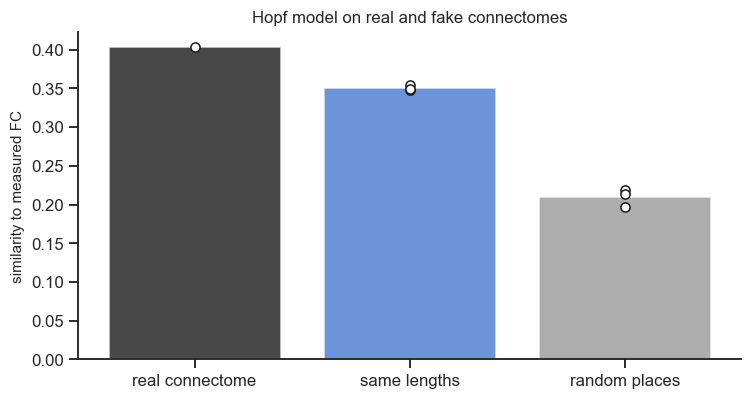

real connectome: 0.40  same lengths: 0.35  random places: 0.21


In [4]:
# @title Fit the same Hopf model with each connectome (a few seconds)
scores = {name: [fit(M) for M in Ms] for name, Ms in fakes.items()}
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (name, s) in enumerate(scores.items()):
    ax.bar(k, np.mean(s), color=["k", "C0", "0.6"][k], alpha=0.8)
    ax.plot(np.full(len(s), k), s, "o", c="w", mec="k", ms=6)
ax.set_xticks(range(3), list(scores)); ax.set(ylabel="similarity to measured FC", title="Hopf model on real and fake connectomes")
plt.tight_layout(); plt.show()
print("  ".join(f"{k}: {np.mean(v):.2f}" for k, v in scores.items()))

Connecting the wrong pairs of regions costs about half of the fit. Keeping only the **length** of each connection
recovers most of it: much of what the connectome gives to FC comes from **geometry**, nearby regions being wired and
therefore correlated (Roberts et al. 2016; Pang et al. 2023). But the real connectome still wins: the hypothesis is
only **partly** right, and the specific pairs carry the rest.

## 3. Cortical gradients: from sensation to abstraction

> **Gist.** As in the slides, many properties of the cortex change smoothly from sensory to association areas. We
> compute the **principal gradient** of the measured FC, and compare it with an anatomical map measured without any
> activity: intracortical **myelin** (MRI T1w/T2w ratio; Glasser & Van Essen 2011).

<details><summary>How the FC gradient is computed (for the curious)</summary>

Keep, for each region, its 10% strongest FC values; compute the cosine similarity between the FC patterns of every
pair of regions; the gradients are the leading components of a **diffusion map** of this similarity (as in the
BrainSpace toolbox, Vos de Wael et al. 2020): a nonlinear version of principal component analysis. Myelin here is the
myelin **inside the grey matter**, a marker of the type of cortical area, not the myelin of the white-matter fibres.
</details>

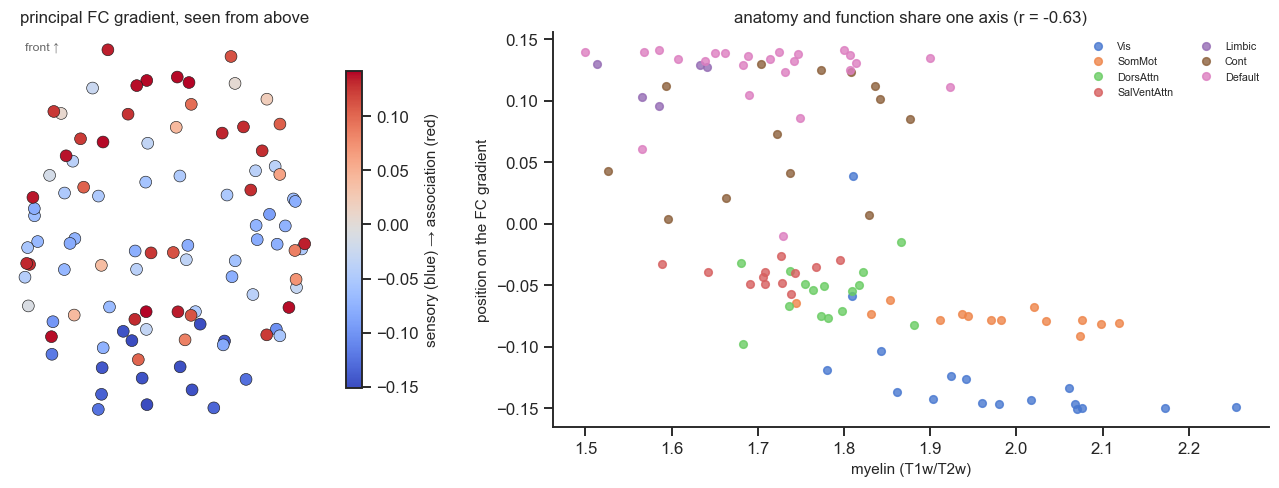

In [5]:
# @title Principal FC gradient on the brain, and against intracortical myelin
def fc_gradients(M, keep=0.1, alpha=0.5, n=2):
    M = M.copy(); np.fill_diagonal(M, 0)
    X = np.where(M >= np.quantile(M, 1 - keep, axis=1, keepdims=True), M, 0)       # keep each row's strongest 10%
    X = X / np.linalg.norm(X, axis=1, keepdims=True); K = np.clip(X @ X.T, 0, None)   # cosine similarity
    dg = K.sum(1); P = K / np.outer(dg**alpha, dg**alpha); P /= P.sum(1, keepdims=True)  # diffusion operator
    ev, vec = np.linalg.eig(P); o = np.argsort(-ev.real)
    return vec.real[:, o[1:n + 1]]

grad = fc_gradients(fc)[:, 0]
grad = grad * np.sign(grad[net == "Default"].mean())               # convention: default mode network at the top
myelin = np.loadtxt("../data/connectome/myelin_t1wt2w_schaefer_100.csv", comments="#")   # one value per region
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
s_ = brain(ax[0], grad, cmap="coolwarm", title="principal FC gradient, seen from above")
plt.colorbar(s_, ax=ax[0], shrink=0.8, label="sensory (blue) → association (red)")
for n in NETS:
    ax[1].plot(myelin[net == n], grad[net == n], "o", c=NETCOL[n], ms=5, alpha=0.8, label=n)
ax[1].set(xlabel="myelin (T1w/T2w)", ylabel="position on the FC gradient",
          title=f"anatomy and function share one axis (r = {np.corrcoef(myelin, grad)[0, 1]:.2f})")
ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Left:** blue (sensory end) at the back of the brain and along the central strip, red (association end) in front
and on the sides. **Right:** one dot per region. Visual and somatomotor regions sit at the sensory end of the FC gradient and are heavily myelinated; default mode and
limbic regions sit at the association end with little myelin. A functional map and an anatomical map line up. In
**NB13b** we use the myelin map to make the regions of the model different from each other.

## 4. Take-home

* The connectome has **hubs** and mostly **short** connections (and a small-world, modular organisation).
* Virtual experiment: a large part of what the model needs from the wiring is **geometry** (connection length); the
  specific pairs give the rest.
* The cortex is organised along a sensory → association **gradient**; anatomy (myelin) and function (FC) share it.
* **Next (NB13b):** let the myelin map set how each region behaves.

### Homework
*To do at home, after the class. These exercises need a few lines of your own code.*
1. **Rich club.** Do hubs connect preferentially to each other? Take the 12 regions with the highest strength and compare
   the density of connections among them with the density of the whole network (van den Heuvel & Sporns 2011).
2. **Structure vs function.** Correlate `np.log1p(sc)` with the measured FC over all pairs. Is the correlation higher
   for short or for long connections?
3. **Distance alone.** Build a connectome from distance only, $W_{ij}=e^{-D_{ij}/\lambda}$ with $\lambda=20$ mm, and
   use `fit` from section 2. Try $\lambda=10$ and $30$ mm.
4. **Small world and same degrees.** With `import networkx as nx`: keep the 40% strongest connections, build a graph
   (`nx.from_numpy_array`), and compare `nx.average_clustering` and `nx.average_shortest_path_length` with a copy
   rewired by `nx.double_edge_swap` (every region keeps its number of connections, partners random). Then give the
   rewired copy, with fibre counts, to `fit`: how does it compare with "random places"?
5. **Myelin and hubs.** Are hubs (high strength) strongly or weakly myelinated?

### References
* Sporns O (2011). *Networks of the Brain*. MIT Press. Bullmore E, Sporns O (2012). The economy of brain network
  organization. *Nat Rev Neurosci* 13:336–349.
* Watts DJ, Strogatz SH (1998). Collective dynamics of 'small-world' networks. *Nature* 393:440–442.
* van den Heuvel MP, Sporns O (2011). Rich-club organization of the human connectome. *J Neurosci* 31:15775–15786.
* Roberts JA et al. (2016). The contribution of geometry to the human connectome. *NeuroImage* 124:379–393.
* Pang JC et al. (2023). Geometric constraints on human brain function. *Nature* 618:566–574.
* Margulies DS et al. (2016). Situating the default-mode network along a principal gradient of macroscale cortical
  organization. *PNAS* 113:12574–12579.
* Huntenburg JM, Bazin P-L, Margulies DS (2018). Large-scale gradients in human cortical organization. *Trends Cogn Sci*
  22:21–31.
* Vos de Wael R et al. (2020). BrainSpace: a toolbox for the analysis of macroscale gradients in neuroimaging and
  connectomics datasets. *Commun Biol* 3:103.
* Glasser MF, Van Essen DC (2011). Mapping human cortical areas in vivo based on myelin content as revealed by T1- and
  T2-weighted MRI. *J Neurosci* 31:11597–11616.
* Yeo BTT et al. (2011). The organization of the human cerebral cortex estimated by intrinsic functional connectivity.
  *J Neurophysiol* 106:1125–1165. Schaefer A et al. (2018). *Cereb Cortex* 28:3095–3114.
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698–700.